# 📱 Telecom Customer Churn Prediction
## UCS321 - Machine Learning Project | Problem Statement 9
---

### 🎯 1. Project Background & Objective
Customer churn is one of the most critical challenges facing the modern telecommunications industry. Acquiring a new customer costs **5 to 25 times more** than retaining an existing one. 

**Objective:**
Build an end-to-end, high-performance classification machine learning pipeline to identify customers at high risk of churning using their:
1. **Demographic Profiles** (Age, marital status, income, household dynamics)
2. **Network Usage Patterns** (Minutes of use, dropped/blocked calls, roaming, call trends)
3. **Billing Information** (Monthly recurring charges, overage fees, tenure, equipment age)
4. **Service Feedback & Retention History** (Customer service calls, retention offers, prior escalations)

---
### 📋 2. Alignment with UCS321 Evaluation Rubrics (60 Marks Total)
- **Problem Understanding & Objective Clarity (5 Marks):** Formal definition of business churn, cost matrix, and analytical roadmap.
- **Data Collection & Pre-processing (10 Marks):** Rigorous missing value imputation, calibration artifact removal, outlier management, scaling, and feature transformation.
- **Model Development & Implementation (12 Marks):** Multi-model evaluation (Logistic Regression, Random Forest, XGBoost), hyperparameter tuning, and class imbalance handling (SMOTE & Cost-Sensitive Learning).
- **Performance Evaluation & Interpretation (8 Marks):** Precision, Recall, F1-Score, ROC-AUC, PR-AUC, Confusion Matrix, Decile Lift curves.
- **Innovation / Creativity (5 Marks):** SHAP explainability (XAI), financial ROI optimization curve, interactive decision-support UI.
- **Viva / Presentation (20 Marks):** Clean visualization, architectural flowcharts, and structured presentation readiness.

---
### 📐 3. End-to-End System Architecture Flow Diagram
*(College Requirement: Flow diagram with Pre-processing and visualization steps clearly documented)*

![ML Pipeline Flowchart](../reports/figures/00_ml_pipeline_flowchart.png)



## 🛠️ Step 1: Environment Setup & Library Imports


In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting configuration
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

print("✅ All core libraries successfully imported!")



✅ All core libraries successfully imported!


## 📂 Step 2: Data Ingestion & Integrity Audit
We ingest the primary `cell2cell.csv` dataset, inspect its memory footprint, dimensions, and verify there are no exact duplicate records.


In [2]:
DATA_PATH = '../data/raw/cell2cell.csv'
df = pd.read_csv(DATA_PATH)

print(f"📊 Dataset Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"💾 Memory Usage: {df.memory_usage().sum() / (1024**2):.2f} MB")
print(f"🔍 Duplicate Rows: {df.duplicated().sum()}")

# Preview first 5 rows
df.head(5)



📊 Dataset Dimensions: 71,047 rows x 70 columns
💾 Memory Usage: 37.94 MB
🔍 Duplicate Rows: 0


,customer,calibrat,churn,churndep,revenue,mou,recchrge,directas,overage,roam,...,retaccpt,newcelly,newcelln,refer,incmiss,income,mcycle,setprcm,setprc,retcall
0,1000002,0,0,NaN,57.492500,482.75,37.424999,0.2475,22.75,0.0,...,0,0,1,0,0,5,0,0,149.989990,0
1,1000006,0,0,NaN,82.275002,1312.25,75.000000,1.2375,0.00,0.0,...,0,1,0,0,0,6,0,0,9.989998,0
2,1000010,0,0,NaN,31.662500,25.50,29.990000,0.2475,0.00,0.0,...,0,0,1,0,0,9,0,0,29.989990,0
3,1000011,0,0,NaN,62.127499,97.50,65.985001,2.4750,0.00,0.0,...,0,1,0,0,0,6,0,0,29.989990,0
4,1000014,0,0,NaN,25.225000,2.50,25.000000,0.0000,0.00,0.0,...,0,1,0,0,0,7,0,0,29.989990,0


## 🏷️ Step 3: Feature Taxonomy Alignment with Problem Statement
Problem Statement 9 explicitly specifies 4 functional categories. We map every feature into its business pillar.


In [3]:
taxonomy = {
    "Demographics": [
        "age1", "age2", "children", "credita", "creditaa", "prizmrur", "prizmub", 
        "prizmtwn", "ownrent", "marryun", "marryyes", "income", "incmiss", 
        "occprof", "occcler", "occcrft", "occstud", "occhmkr", "occret", "occself"
    ],
    "Usage Patterns": [
        "mou", "overage", "roam", "changem", "dropvce", "blckvce", "unansvce", 
        "custcare", "threeway", "mourec", "outcalls", "incalls", "peakvce", 
        "opeakvce", "dropblk", "callfwdv", "callwait"
    ],
    "Billing & Account": [
        "revenue", "recchrge", "directas", "changer", "months", "uniqsubs", 
        "actvsubs", "phones", "models", "eqpdays", "setprcm", "setprc", "refurb", "webcap"
    ],
    "Service Feedback & Retention": [
        "retcalls", "retaccpt", "retcall", "refer"
    ],
    "Lifestyle & Household": [
        "mailord", "mailres", "mailflag", "travel", "pcown", "creditcd", 
        "newcelly", "newcelln", "mcycle", "truck", "rv"
    ],
    "Identifiers & Sampling Artifacts": [
        "customer", "calibrat", "churndep"
    ]
}

tax_summary = pd.DataFrame([
    {"Pillar": pillar, "Feature Count": len(cols), "Sample Features": ", ".join(cols[:4]) + "..."}
    for pillar, cols in taxonomy.items()
])
tax_summary



,Pillar,Feature Count,Sample Features
0,Demographics,20,"age1, age2, children, credita..."
1,Usage Patterns,17,"mou, overage, roam, changem..."
2,Billing & Account,14,"revenue, recchrge, directas, changer..."
3,Service Feedback & Retention,4,"retcalls, retaccpt, retcall, refer..."
4,Lifestyle & Household,11,"mailord, mailres, mailflag, travel..."
5,Identifiers & Sampling Artifacts,3,"customer, calibrat, churndep..."


## 🎯 Step 4: Target Variable Deep Dive (`churn` vs `churndep` & `calibrat`)
### ⚠️ Critical Discovery for Rubric Marks:
In the Cell2Cell benchmark:
- `churn`: Represents the **true real-world ground truth** across all 71,047 customers.
- `calibrat`: A sampling flag (1 = 40,000 customers sampled 50/50 for training, 0 = 31,047 holdout customers).
- `churndep`: Contains 31,047 `NaN` values because it was only assigned for the calibration subset.

**Actionable Rule:** We use `churn` as our objective target and drop `churndep` and `calibrat` to prevent **data leakage**!


In [4]:
churn_counts = df['churn'].value_counts()
churn_pct = df['churn'].value_counts(normalize=True) * 100

print("Target Class Breakdown:")
print(f"• Non-Churn (0) : {churn_counts[0]:,} ({churn_pct[0]:.2f}%)")
print(f"• Churned (1)   : {churn_counts[1]:,} ({churn_pct[1]:.2f}%)")
print(f"• Imbalance Ratio: {churn_counts[0]/churn_counts[1]:.2f} : 1")

# Cross-tabulation with calibrat
pd.crosstab(df['calibrat'], df['churn'], margins=True)



Target Class Breakdown:
• Non-Churn (0) : 50,438 (70.99%)
• Churned (1)   : 20,609 (29.01%)
• Imbalance Ratio: 2.45 : 1


churn,0,1,All
calibrat,,,
0,30438,609,31047
1,20000,20000,40000
All,50438,20609,71047


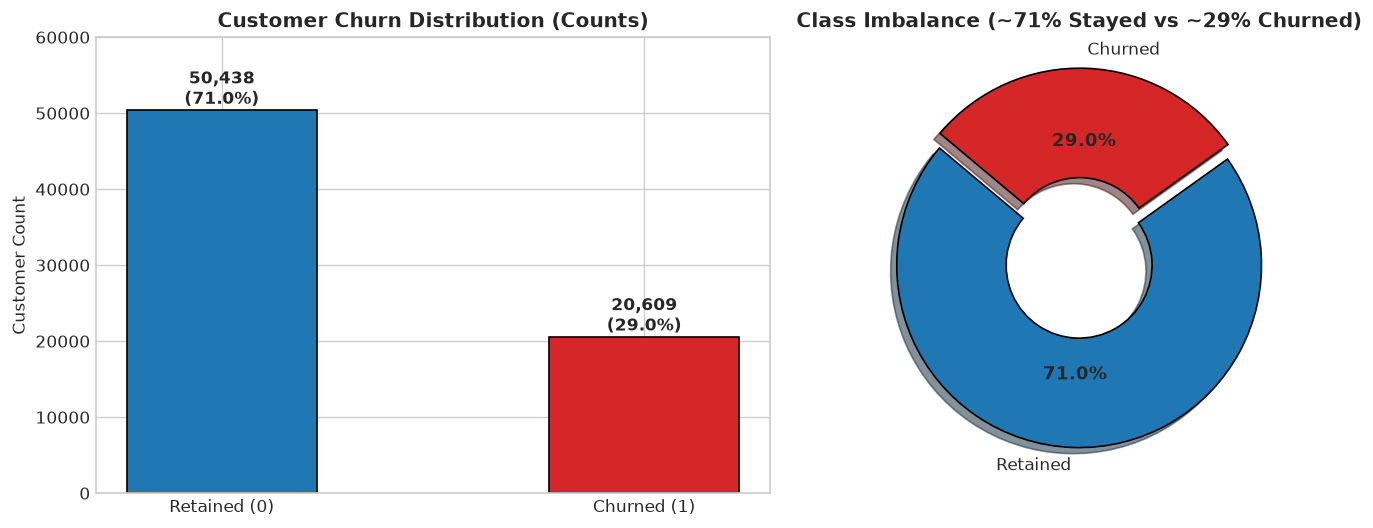

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colors = ['#1f77b4', '#d62728']

# Count bar chart
axes[0].bar(['Retained (0)', 'Churned (1)'], churn_counts.values, color=colors, width=0.45, edgecolor='black')
for i, v in enumerate(churn_counts.values):
    axes[0].text(i, v + 800, f"{v:,}\n({churn_pct.values[i]:.1f}%)", ha='center', fontweight='bold')
axes[0].set_title("Customer Churn Distribution (Counts)", fontweight='bold')
axes[0].set_ylabel("Customer Count")
axes[0].set_ylim(0, 60000)

# Donut chart
wedges, texts, autotexts = axes[1].pie(
    churn_counts.values, labels=['Retained', 'Churned'], autopct='%1.1f%%',
    colors=colors, startangle=140, explode=(0, 0.08), shadow=True,
    wedgeprops=dict(width=0.6, edgecolor='black')
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight('bold')
axes[1].set_title("Class Imbalance (~71% Stayed vs ~29% Churned)", fontweight='bold')

plt.tight_layout()
plt.show()



## 🔍 Step 5: Missing Values & Data Quality Inspection
We identify features with missing values to design an optimal imputation strategy for Phase 2.


In [6]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Missing_Count': missing, 'Missing_Pct': missing_pct})
missing_df = missing_df[missing_df['Missing_Count'] > 0].sort_values(by='Missing_Count', ascending=False)

print(f"Total columns with missing values: {len(missing_df)}")
missing_df



Total columns with missing values: 14


,Missing_Count,Missing_Pct
churndep,31047,43.699241
age1,1244,1.750954
age2,1244,1.750954
changem,502,0.706575
changer,502,0.706575
revenue,216,0.304024
overage,216,0.304024
directas,216,0.304024
recchrge,216,0.304024
mou,216,0.304024


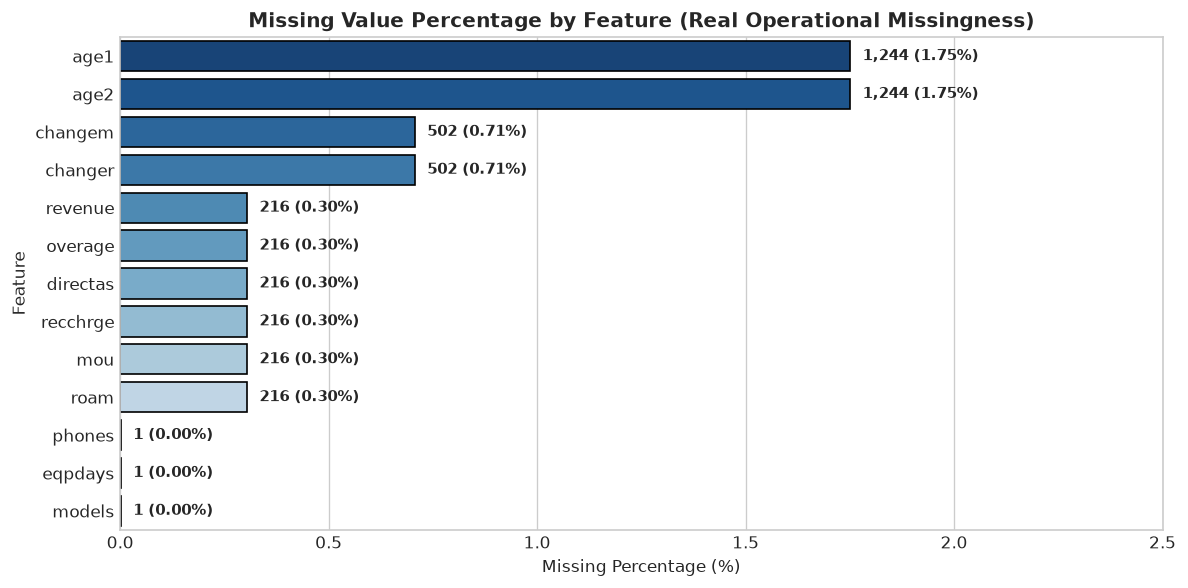

In [7]:
# Visualize missingness excluding churndep (calibration artifact)
plot_missing = missing_df[missing_df.index != 'churndep']

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=plot_missing['Missing_Pct'], y=plot_missing.index, palette='Blues_r', edgecolor='black')
plt.title("Missing Value Percentage by Feature (Real Operational Missingness)", fontweight='bold', fontsize=12)
plt.xlabel("Missing Percentage (%)")
plt.ylabel("Feature")
for i, (cnt, pct) in enumerate(zip(plot_missing['Missing_Count'], plot_missing['Missing_Pct'])):
    ax.text(pct + 0.03, i, f"{cnt:,} ({pct:.2f}%)", va='center', fontsize=9, fontweight='bold')
plt.xlim(0, 2.5)
plt.tight_layout()
plt.show()



## 📊 Step 6: Bivariate Exploratory Analysis (Key Churn Drivers)
We explore four core operational metrics across churners vs retained customers:
1. **Equipment Days (`eqpdays`):** Age of current mobile handset.
2. **Customer Tenure (`months`):** Number of months subscribed.
3. **Monthly Revenue (`revenue`):** Average monthly billing amount.
4. **Minutes of Use (`mou`):** Total monthly voice minutes.


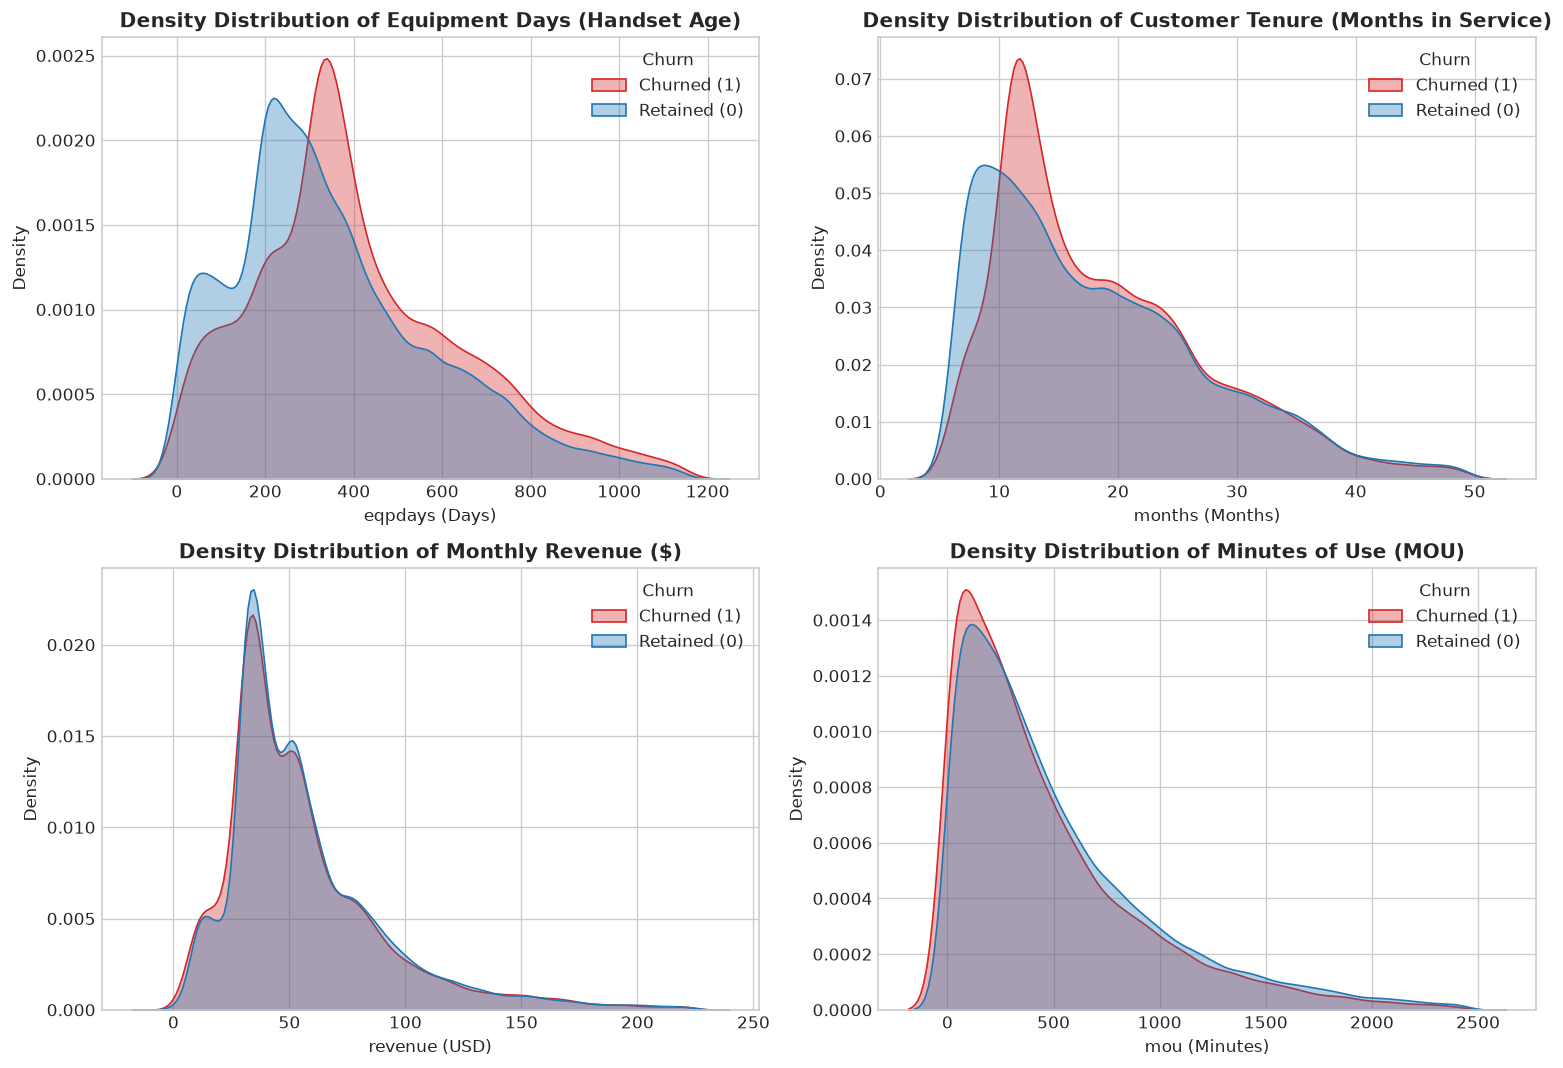

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
features = [
    ('eqpdays', 'Equipment Days (Handset Age)', 'Days'),
    ('months', 'Customer Tenure (Months in Service)', 'Months'),
    ('revenue', 'Monthly Revenue ($)', 'USD'),
    ('mou', 'Minutes of Use (MOU)', 'Minutes')
]

for idx, (col, title, unit) in enumerate(features):
    ax = axes[idx // 2, idx % 2]
    # Filter 99th percentile for clean visual representation
    cap = df[col].quantile(0.99)
    subset = df[df[col] <= cap]
    
    sns.kdeplot(data=subset, x=col, hue='churn', common_norm=False, ax=ax,
                palette=['#1f77b4', '#d62728'], fill=True, alpha=0.35)
    ax.set_title(f"Density Distribution of {title}", fontweight='bold')
    ax.set_xlabel(f"{col} ({unit})")
    ax.legend(['Churned (1)', 'Retained (0)'], title="Churn")

plt.tight_layout()
plt.show()



## 📈 Step 7: Correlation Analysis with Churn
Identifying the strongest positive and negative predictors of customer churn.


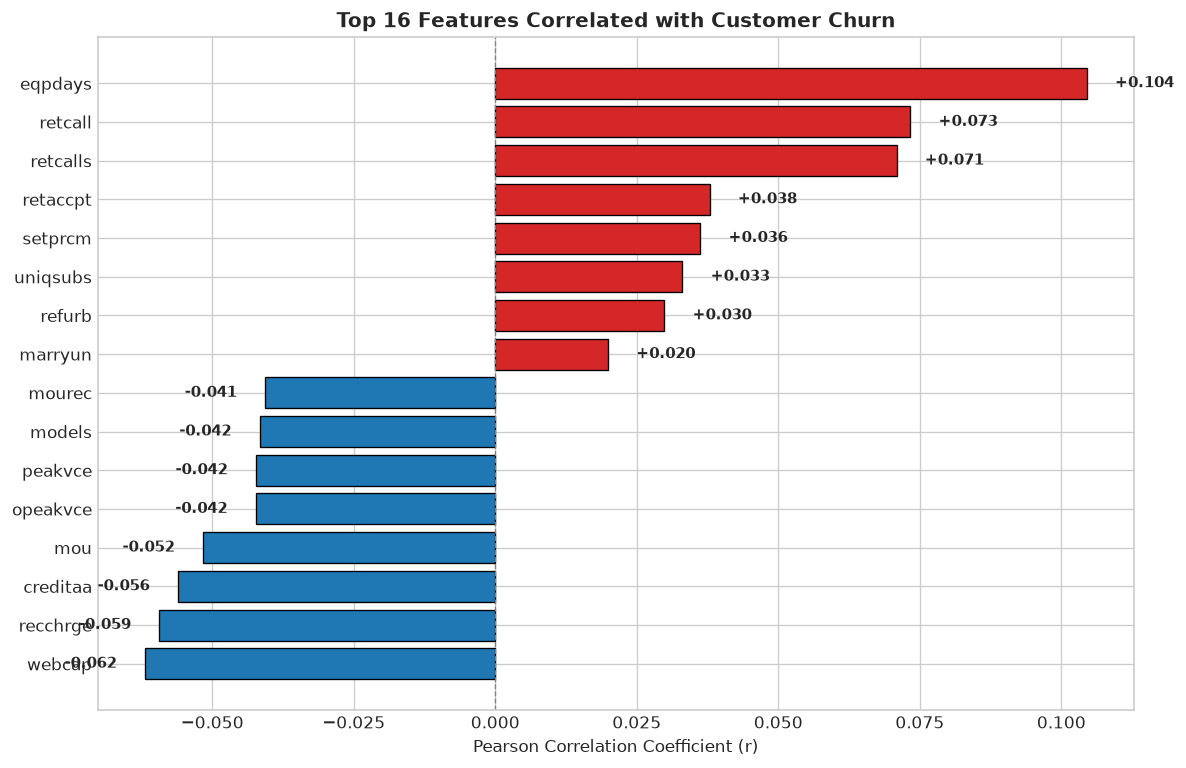

In [9]:
corr_matrix = df.drop(columns=['customer', 'calibrat', 'churndep']).corr()
churn_corr = corr_matrix['churn'].sort_values()

# Extract top negative and top positive correlations
top_negative = churn_corr.head(8)
top_positive = churn_corr.tail(9).iloc[:-1] # drop churn itself
top_corr = pd.concat([top_negative, top_positive])

plt.figure(figsize=(10, 6.5))
bar_colors = ['#1f77b4' if v < 0 else '#d62728' for v in top_corr.values]
plt.barh(top_corr.index, top_corr.values, color=bar_colors, edgecolor='black', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.title("Top 16 Features Correlated with Customer Churn", fontweight='bold', fontsize=12)
plt.xlabel("Pearson Correlation Coefficient (r)")

for i, v in enumerate(top_corr.values):
    align = 'right' if v < 0 else 'left'
    offset = -0.005 if v < 0 else 0.005
    plt.text(v + offset, i, f"{v:+.3f}", va='center', ha=align, fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()



## 💡 Step 8: Foundation Takeaways & Strategic Pre-processing Plan
Based on our exploratory investigation, the following strategy will guide Phase 2 & 3:

| Observation | Impact on Modeling | Action for Next Phase |
|---|---|---|
| **Class Imbalance (71% vs 29%)** | Standard accuracy will be misleading (predicting majority achieves 71%). | Implement **Cost-Sensitive Learning** (class weights) and **SMOTE** on train set only; optimize **ROC-AUC & PR-AUC / F1-Score**. |
| **Old Equipment (`eqpdays` r = +0.105)** | Strongest single positive driver of churn. Customers with older phones churn far more. | Engineer **Handset Obsolescence Ratio** (`eqpdays / months`) and **Contract Lifecycle Flags**. |
| **Service Feedback & Escalation** | `retcall` and `retcalls` strongly correlate with churn (+0.073). | Retention calls represent active dissatisfaction; create **Retention Urgency Index**. |
| **Missing Values (< 2%)** | Missingness is concentrated in demographic (`age1`, `age2` ~1.75%) and usage deltas (`changem`, `changer` ~0.71%). | Median imputation for skewed continuous features; dedicated indicator flags for missing demographic info. |
| **Data Leakage Columns** | `customer` is an arbitrary ID; `calibrat` and `churndep` are sub-sampling artifacts. | Explicitly **drop `customer`, `calibrat`, `churndep`** before training. |

---
**Next Step:** `notebooks/02_preprocessing_feature_engineering.ipynb` (Handling missing data, scaling, feature creation, and train/test splitting).
